LUNG ATLAS
===

IMPORT LIBRARIES
==

In [2]:
import scanpy as sc
import scrublet as scr
import scvi
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
import matplotlib.lines as mlines
import matplotlib.colors as mcolors
import os
import time
import warnings
from pathlib import Path
from sklearn.metrics import silhouette_score

/gpfs/projects/kawaldorflab/software/miniconda3/envs/scANVI/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
torch.cuda.is_available()

True

In [1]:
import sys, importlib.metadata as md
print(sys.version)
for p in ["scanpy", "anndata", "scvi-tools", "torch", "scrublet", "numpy", "pandas", "leidenalg", "igraph", "umap-learn"]:
    try: print(p, md.version(p))
    except md.PackageNotFoundError: print(p, "not installed")

3.10.19 (main, Oct 21 2025, 16:43:05) [GCC 11.2.0]
scanpy 1.11.5
anndata 0.11.4
scvi-tools 1.3.3
torch 2.9.1
scrublet 0.2.3
numpy 2.2.6
pandas 2.3.3
leidenalg 0.10.2
igraph 0.11.9
umap-learn 0.5.9.post2


CONFIGURATION
==

In [4]:
DATA_DIR = '/gpfs/projects/kawaldorflab/tykim/python_files/Lung_Atlas/cellbender_results/'
H5_FILES = {}
for f in sorted(Path(DATA_DIR).glob('*cellbender_filtered.h5')):
    sample_name = f.stem
    donor = sample_name.split('_')[1]
    if donor.startswith('Z'):
        H5_FILES[sample_name] = str(f)

print(f"Selected {len(H5_FILES)} samples:")
for s in H5_FILES:
    print(f"   {s}")
assert len(H5_FILES) == 5, f"Expected 5 samples, got {len(H5_FILES)}"

OUTPUT_PATH = '/gpfs/projects/kawaldorflab/tykim/python_files/Lung_Atlas/output/scanvi_output_v2.h5ad'
MODEL_SAVE_DIR = '/gpfs/projects/kawaldorflab/tykim/python_files/Lung_Atlas/models_v2/'
FIGURES_DIR = '/gpfs/projects/kawaldorflab/tykim/python_files/Lung_Atlas/figures_v2/'
QC_FIGURES_DIR = '/gpfs/projects/kawaldorflab/tykim/python_files/Lung_Atlas/figures_v2/QC'
MARKER_GENES_CSV = os.path.join(FIGURES_DIR, 'marker_genes.csv')

os.makedirs(MODEL_SAVE_DIR, exist_ok=True)
os.makedirs(FIGURES_DIR, exist_ok=True)
os.makedirs(QC_FIGURES_DIR, exist_ok=True)

SEED = 42
np.random.seed(SEED)
scvi.settings.seed = SEED
torch.manual_seed(SEED)
torch.cuda.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False
os.environ['PYTHONHASHSEED'] = str(SEED)

[rank: 0] Seed set to 42


Selected 5 samples:
   CTRL_Z14378np_lung_ZS_run15_cellbender_filtered
   CTRL_Z16180np_lung_ZS_run11_cellbender_filtered
   CTRL_Z17134np_lung_ZS_run15_cellbender_filtered
   CTRL_Z21174np_lung_ZS_run13_cellbender_filtered
   CTRL_Z22003np_lung_ZS_run13_cellbender_filtered


LOAD SAMPLES
==

In [5]:
adata_list = []
for sample_name, h5_path in H5_FILES.items():
    print(f"\nLoading {sample_name} from {h5_path}")

    with warnings.catch_warnings():
        warnings.simplefilter("ignore", UserWarning)
        adata_sample = sc.read_10x_h5(h5_path)

    adata_sample.var_names_make_unique()
    
    adata_sample.obs['sample'] = sample_name
    adata_sample.obs['batch'] = sample_name
    
    if '-' in adata_sample.obs_names[0]:
        gem_groups = [barcode.split('-')[-1] for barcode in adata_sample.obs_names]
        adata_sample.obs['gem_group'] = gem_groups
        unique_gems = set(gem_groups)
        if len(unique_gems) > 1:
            print(f"   Warning: {sample_name} has {len(unique_gems)} GEM groups")
            adata_sample.obs['batch'] = adata_sample.obs.apply(
                lambda x: f"{x['sample']}_GEM{x['gem_group']}", axis=1
            )
    adata_sample.obs_names = [f"{sample_name.replace('_cellbender_filtered', '')}_{bc}" for bc in adata_sample.obs_names]

    print(f"   Cells: {adata_sample.n_obs:,}")
    print(f"   Genes: {adata_sample.n_vars:,}")
    
    adata_list.append(adata_sample)

print(f"\nTotal Number of Samples: {len(adata_list)}")


Loading CTRL_Z14378np_lung_ZS_run15_cellbender_filtered from /gpfs/projects/kawaldorflab/tykim/python_files/Lung_Atlas/cellbender_results/CTRL_Z14378np_lung_ZS_run15_cellbender_filtered.h5
   Cells: 27,385
   Genes: 21,591

Loading CTRL_Z16180np_lung_ZS_run11_cellbender_filtered from /gpfs/projects/kawaldorflab/tykim/python_files/Lung_Atlas/cellbender_results/CTRL_Z16180np_lung_ZS_run11_cellbender_filtered.h5
   Cells: 19,790
   Genes: 21,591

Loading CTRL_Z17134np_lung_ZS_run15_cellbender_filtered from /gpfs/projects/kawaldorflab/tykim/python_files/Lung_Atlas/cellbender_results/CTRL_Z17134np_lung_ZS_run15_cellbender_filtered.h5
   Cells: 21,809
   Genes: 21,591

Loading CTRL_Z21174np_lung_ZS_run13_cellbender_filtered from /gpfs/projects/kawaldorflab/tykim/python_files/Lung_Atlas/cellbender_results/CTRL_Z21174np_lung_ZS_run13_cellbender_filtered.h5
   Cells: 18,055
   Genes: 21,591

Loading CTRL_Z22003np_lung_ZS_run13_cellbender_filtered from /gpfs/projects/kawaldorflab/tykim/python_f

QUALITY CONTROL
==


Processing CTRL_Z14378np_lung_ZS_run15_cellbender_filtered
   Mito genes found: 13


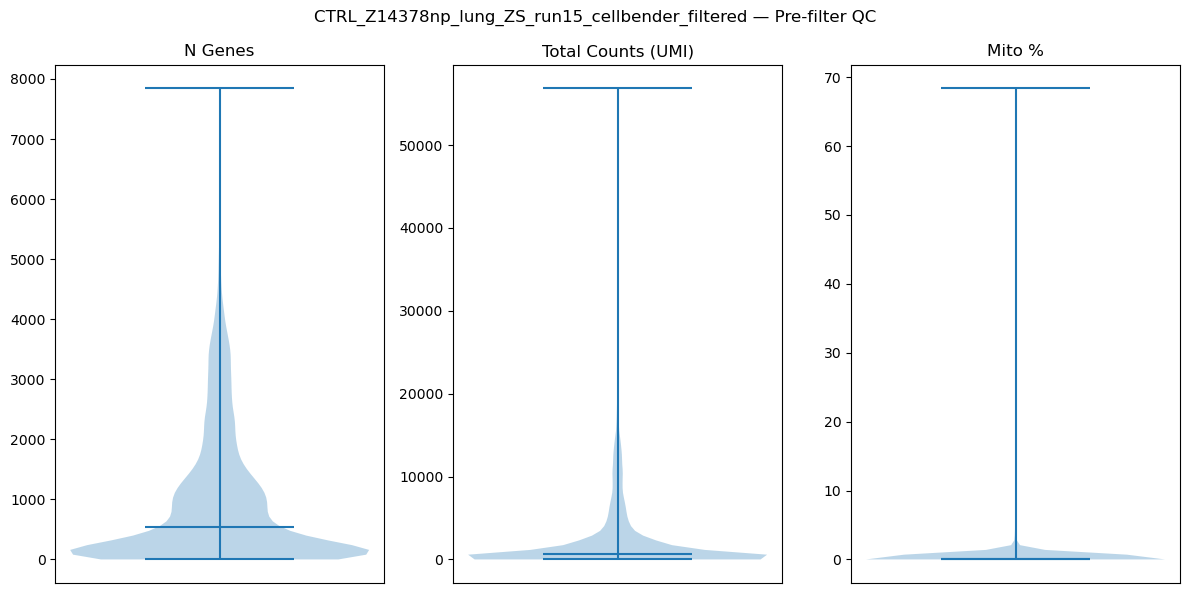

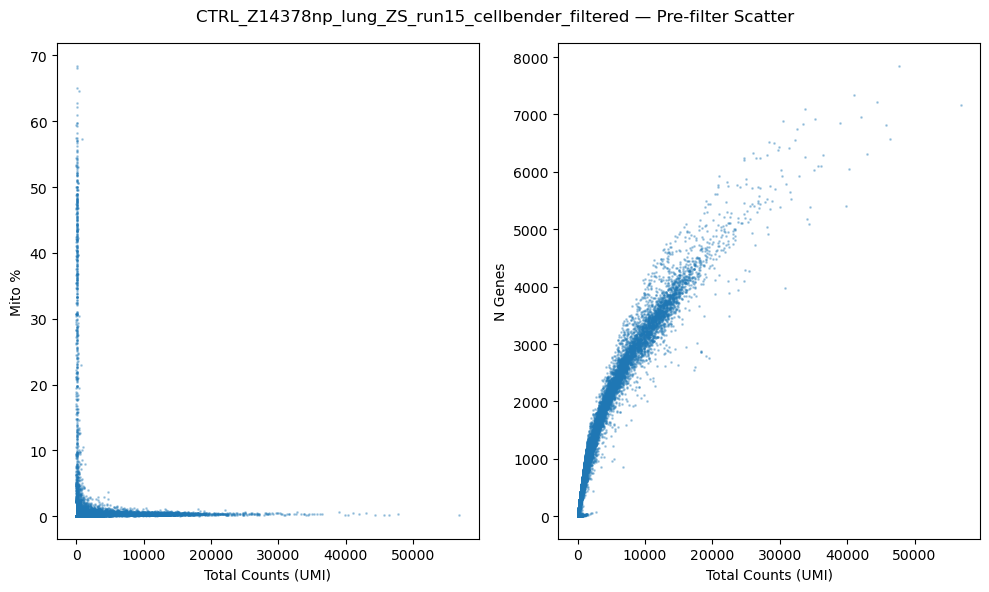

   Cells after QC filter: 15,142 / 27,385 (55.3%)
Preprocessing...
Simulating doublets...
Embedding transcriptomes using PCA...
Calculating doublet scores...
Automatically set threshold at doublet score = 0.68
Detected doublet rate = 0.0%
Estimated detectable doublet fraction = 1.0%
Overall doublet rate:
	Expected   = 5.0%
	Estimated  = 1.3%
Elapsed time: 23.3 seconds
Detected doublet rate = 1.5%
Estimated detectable doublet fraction = 19.0%
Overall doublet rate:
	Expected   = 5.0%
	Estimated  = 8.0%


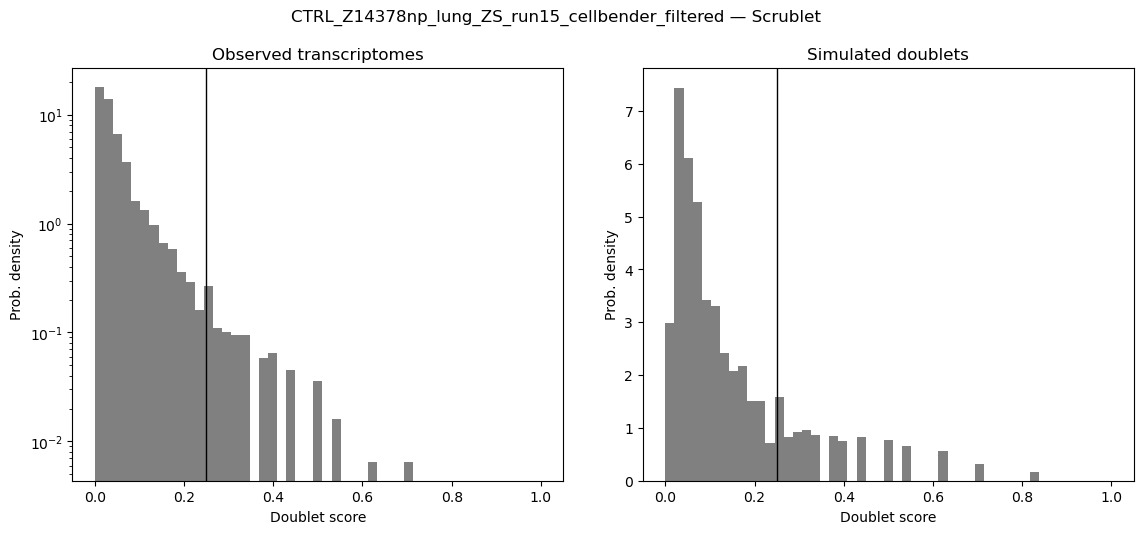

   Doublets removed: 231 (1.5%)
   Final cells: 14,911

Processing CTRL_Z16180np_lung_ZS_run11_cellbender_filtered
   Mito genes found: 13


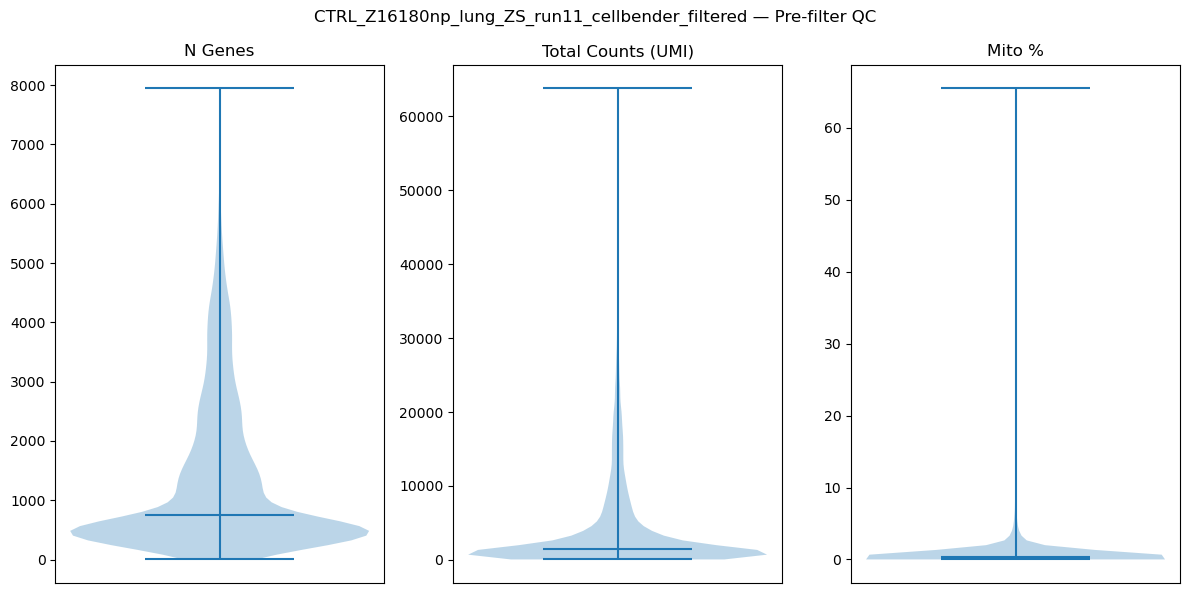

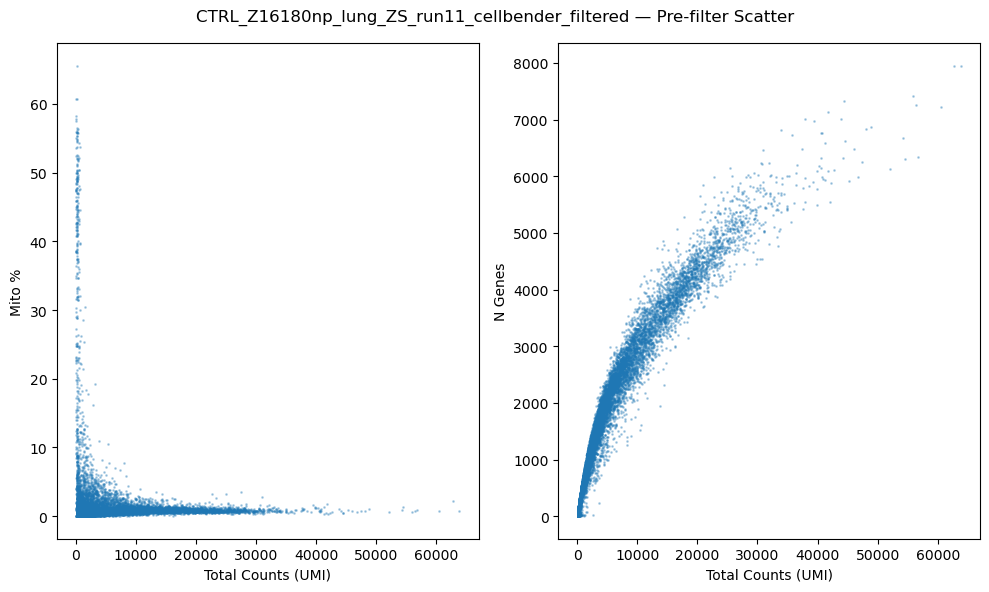

   Cells after QC filter: 16,569 / 19,790 (83.7%)
Preprocessing...
Simulating doublets...
Embedding transcriptomes using PCA...
Calculating doublet scores...
Automatically set threshold at doublet score = 0.65
Detected doublet rate = 0.0%
Estimated detectable doublet fraction = 3.4%
Overall doublet rate:
	Expected   = 5.0%
	Estimated  = 0.4%
Elapsed time: 22.2 seconds
Detected doublet rate = 1.1%
Estimated detectable doublet fraction = 18.1%
Overall doublet rate:
	Expected   = 5.0%
	Estimated  = 5.9%


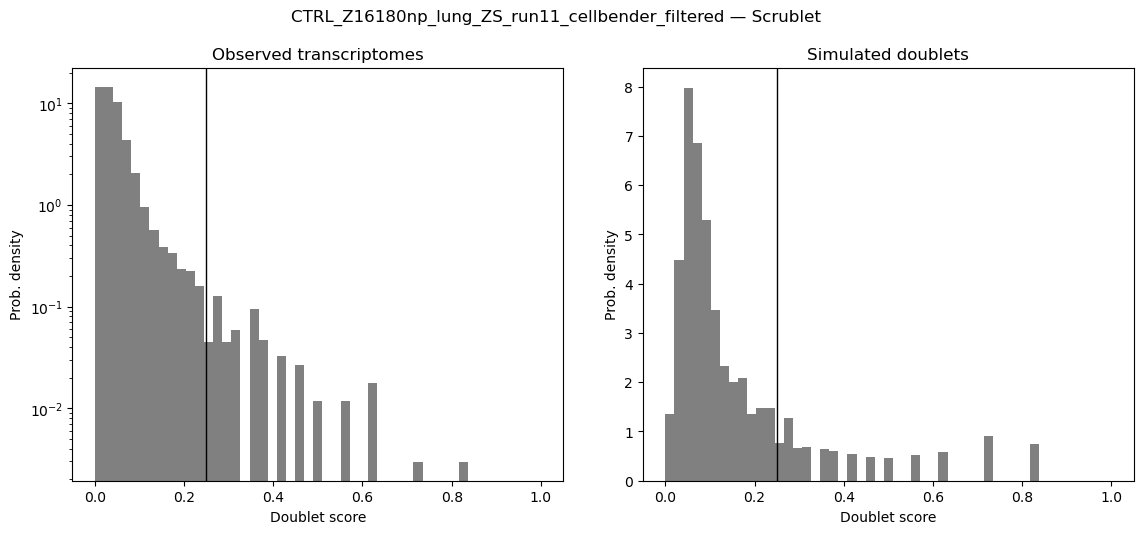

   Doublets removed: 177 (1.1%)
   Final cells: 16,392

Processing CTRL_Z17134np_lung_ZS_run15_cellbender_filtered
   Mito genes found: 13


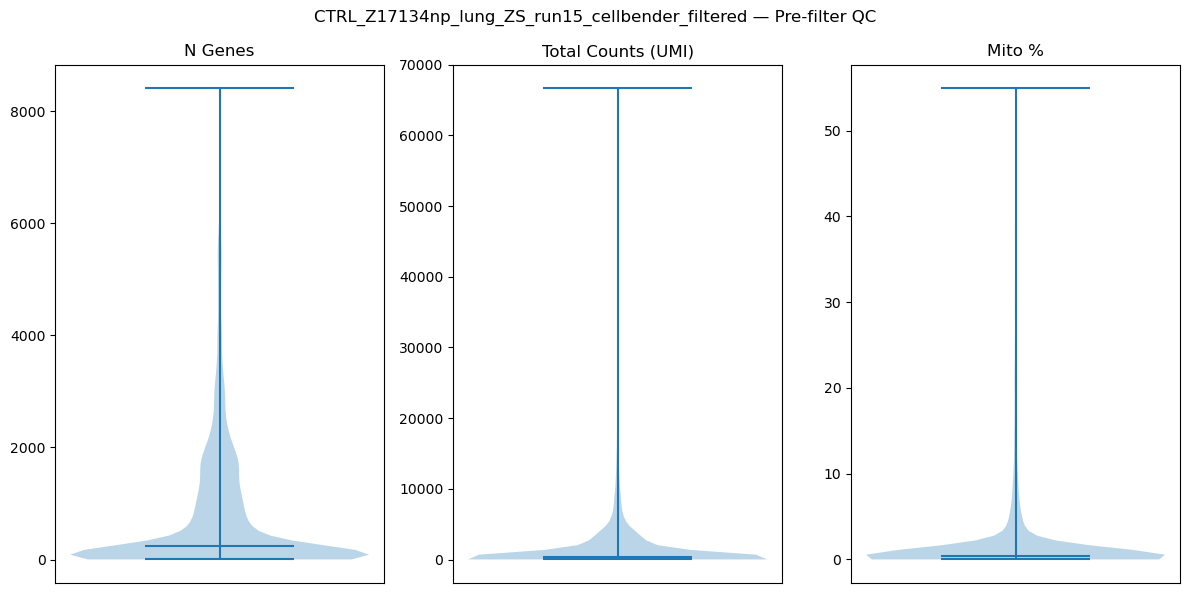

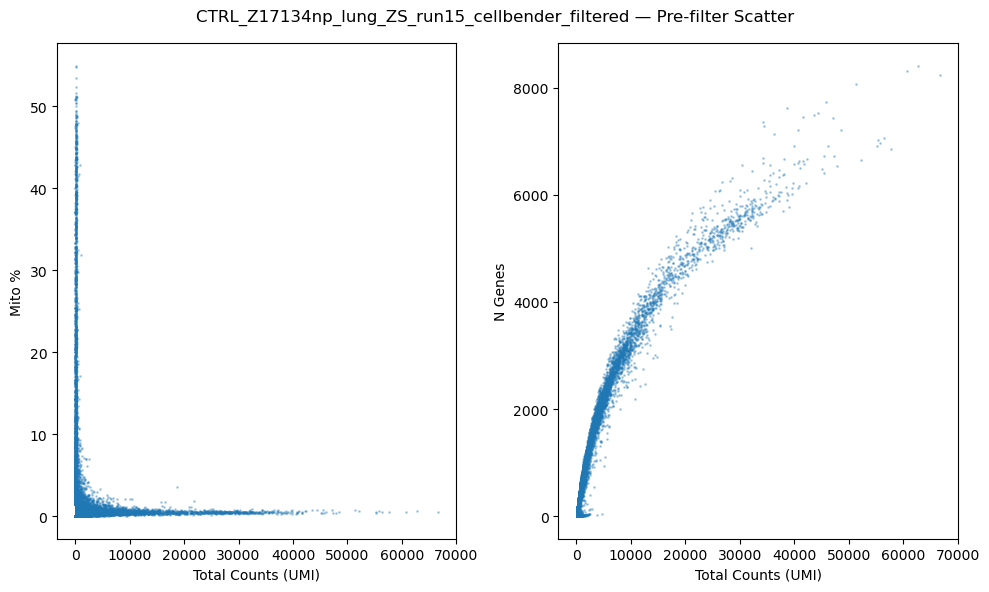

   Cells after QC filter: 9,886 / 21,809 (45.3%)
Preprocessing...
Simulating doublets...
Embedding transcriptomes using PCA...
Calculating doublet scores...
Automatically set threshold at doublet score = 0.62
Detected doublet rate = 0.0%
Estimated detectable doublet fraction = 2.4%
Overall doublet rate:
	Expected   = 5.0%
	Estimated  = 1.7%
Elapsed time: 10.5 seconds
Detected doublet rate = 1.5%
Estimated detectable doublet fraction = 19.1%
Overall doublet rate:
	Expected   = 5.0%
	Estimated  = 8.0%


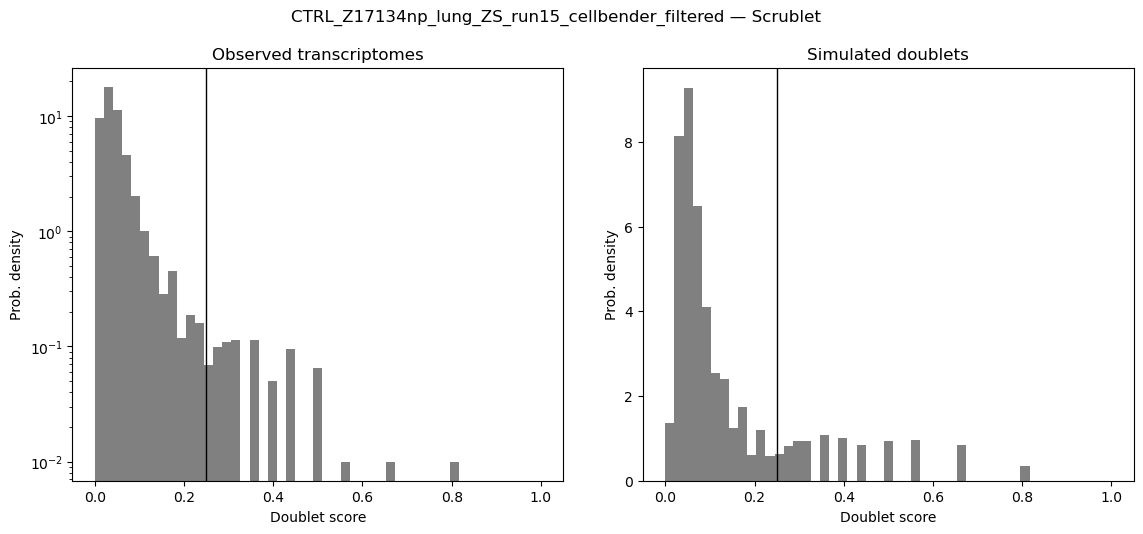

   Doublets removed: 150 (1.5%)
   Final cells: 9,736

Processing CTRL_Z21174np_lung_ZS_run13_cellbender_filtered
   Mito genes found: 13


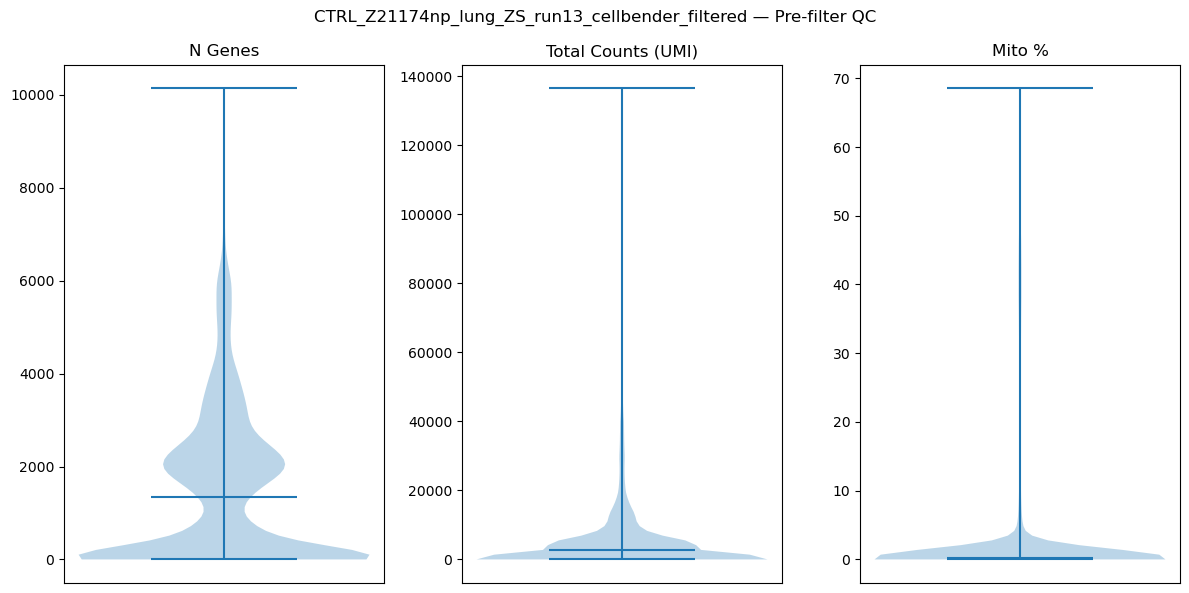

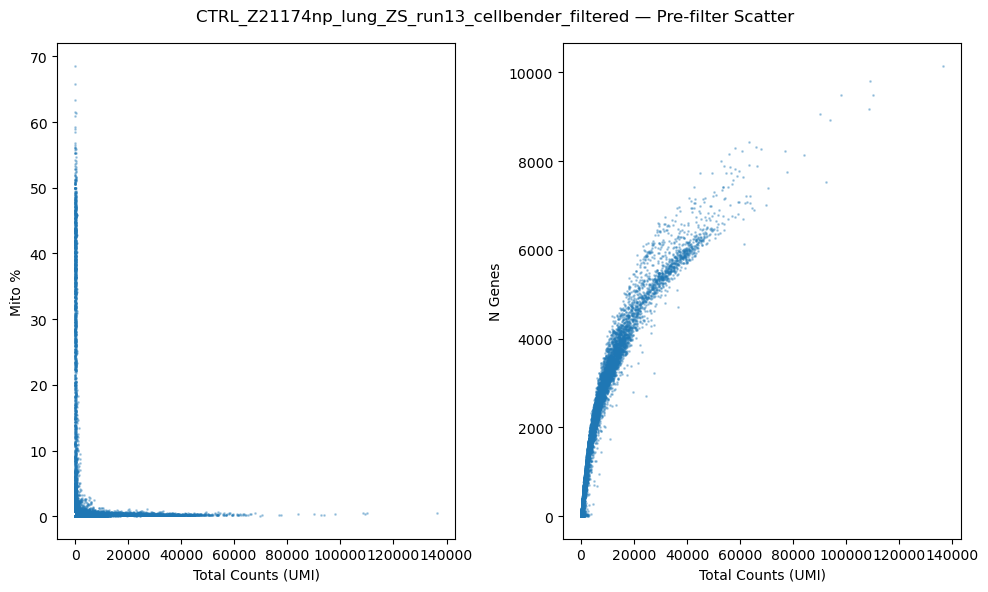

   Cells after QC filter: 11,533 / 18,055 (63.9%)
Preprocessing...
Simulating doublets...
Embedding transcriptomes using PCA...
Calculating doublet scores...
Automatically set threshold at doublet score = 0.65
Detected doublet rate = 0.0%
Estimated detectable doublet fraction = 2.4%
Overall doublet rate:
	Expected   = 5.0%
	Estimated  = 1.4%
Elapsed time: 13.9 seconds
Detected doublet rate = 1.9%
Estimated detectable doublet fraction = 29.1%
Overall doublet rate:
	Expected   = 5.0%
	Estimated  = 6.5%


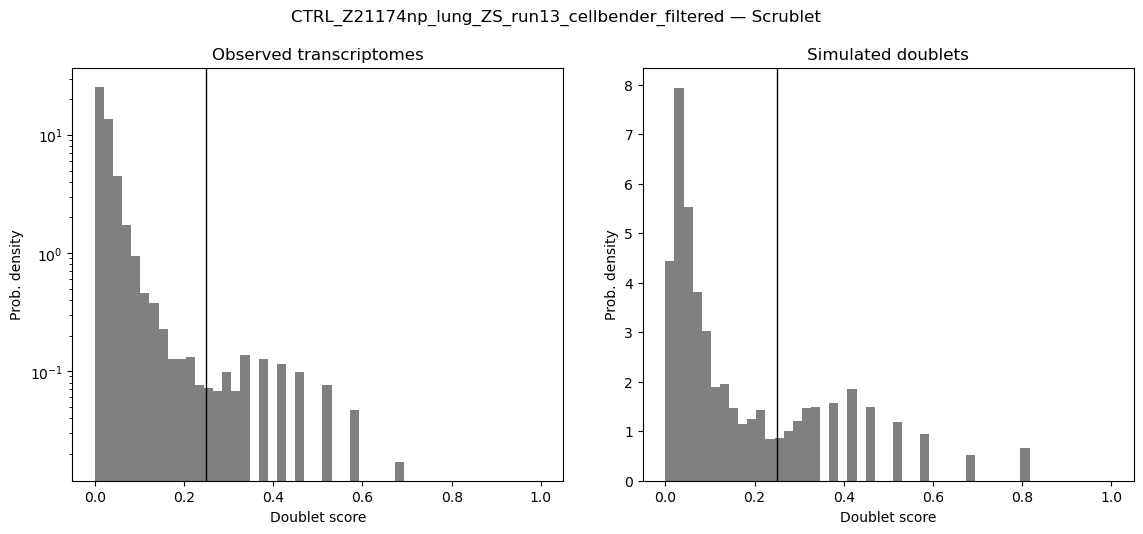

   Doublets removed: 217 (1.9%)
   Final cells: 11,316

Processing CTRL_Z22003np_lung_ZS_run13_cellbender_filtered
   Mito genes found: 13


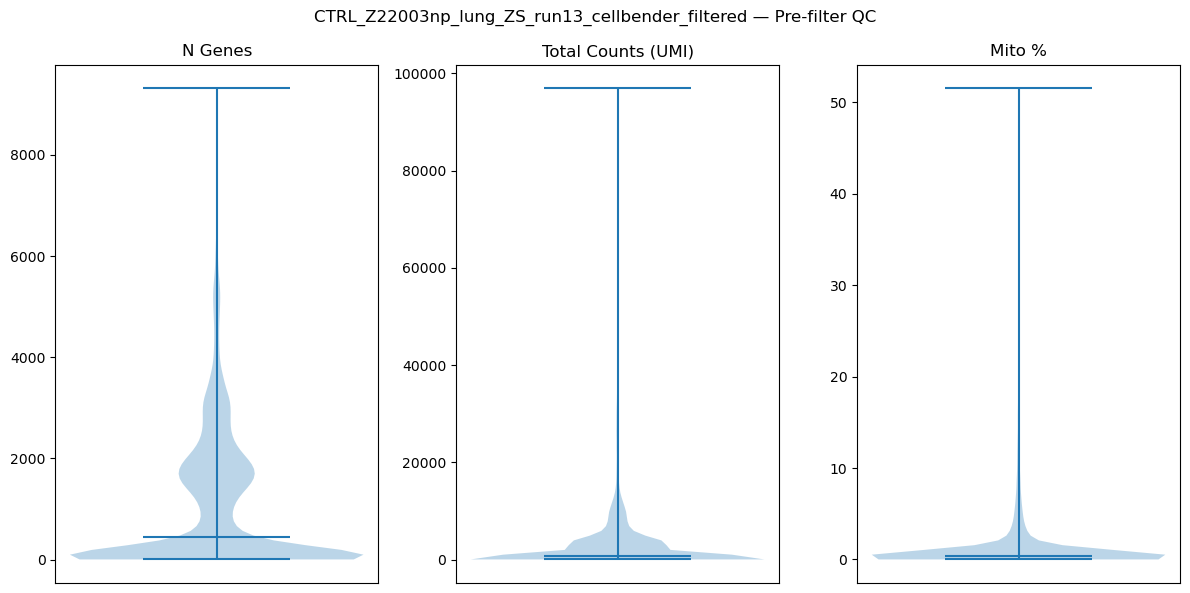

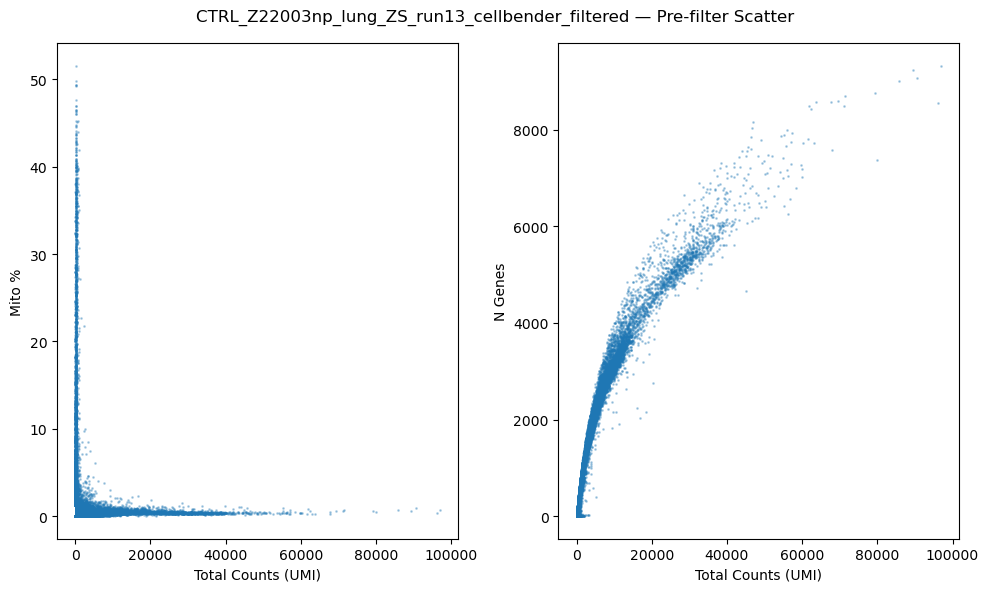

   Cells after QC filter: 16,937 / 31,858 (53.2%)
Preprocessing...
Simulating doublets...
Embedding transcriptomes using PCA...
Calculating doublet scores...
Automatically set threshold at doublet score = 0.24
Detected doublet rate = 2.7%
Estimated detectable doublet fraction = 31.5%
Overall doublet rate:
	Expected   = 5.0%
	Estimated  = 8.6%
Elapsed time: 21.4 seconds
Detected doublet rate = 2.5%
Estimated detectable doublet fraction = 29.7%
Overall doublet rate:
	Expected   = 5.0%
	Estimated  = 8.5%


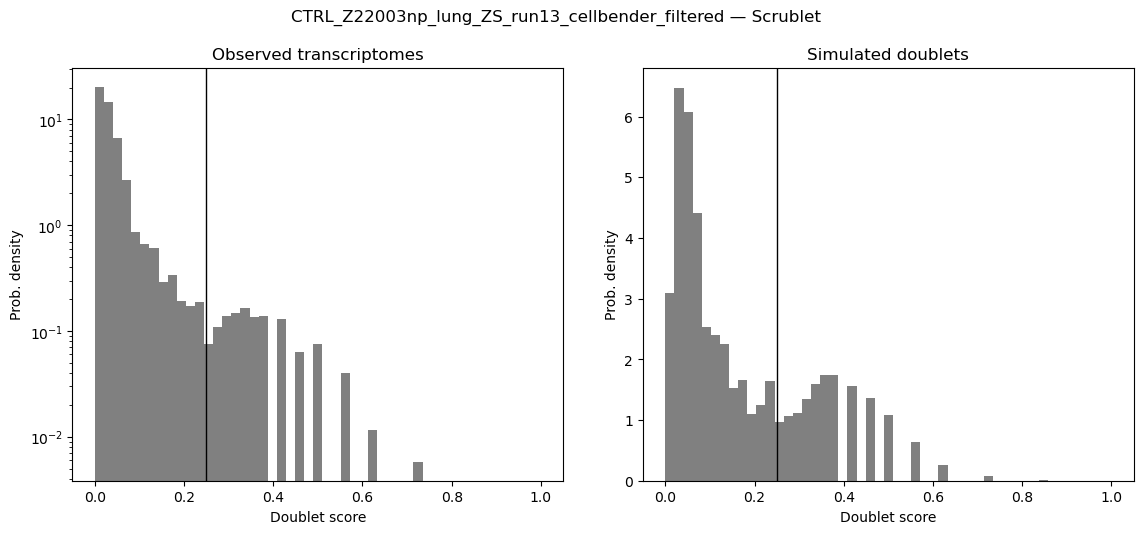

   Doublets removed: 428 (2.5%)
   Final cells: 16,509

Total samples after QC: 5


In [6]:
adata_list_qc = []
for adata_sample in adata_list:
    sample_name = adata_sample.obs['sample'].iloc[0]
    print(f"\nProcessing {sample_name}")

    # ── QC metrics ──────────────────────────────────────────────
    MITO_GENES = {'ND1','ND2','ND3','ND4','ND4L','ND5','ND6','ATP6','ATP8','COX1','COX2','COX3','CYTB'}
    adata_sample.var['mt'] = adata_sample.var_names.isin(MITO_GENES)
    print(f"   Mito genes found: {adata_sample.var['mt'].sum()}")
    sc.pp.calculate_qc_metrics(adata_sample, qc_vars=['mt'], inplace=True)

    # ── Violin plots (pre-filter) ────────────────────────────────
    fig, axes = plt.subplots(1, 3, figsize=(12, 6))
    fig.suptitle(f'{sample_name} — Pre-filter QC', fontsize=12)

    for ax, metric, label in zip(axes,
                                  ['n_genes_by_counts', 'total_counts', 'pct_counts_mt'],
                                  ['N Genes', 'Total Counts (UMI)', 'Mito %']):
        ax.violinplot(adata_sample.obs[metric], showmedians=True)
        ax.set_title(label)
        ax.set_xticks([])

    plt.tight_layout()
    plt.savefig(os.path.join(QC_FIGURES_DIR, f'{sample_name}_violin.png'), dpi=150, bbox_inches='tight')
    plt.show()
    plt.close()

    # ── Scatter plots ────────────────────────────────────────────
    fig, axes = plt.subplots(1, 2, figsize=(10, 6))
    fig.suptitle(f'{sample_name} — Pre-filter Scatter', fontsize=12)

    axes[0].scatter(adata_sample.obs['total_counts'], adata_sample.obs['pct_counts_mt'], s=1, alpha=0.3)
    axes[0].set_xlabel('Total Counts (UMI)')
    axes[0].set_ylabel('Mito %')

    axes[1].scatter(adata_sample.obs['total_counts'], adata_sample.obs['n_genes_by_counts'], s=1, alpha=0.3)
    axes[1].set_xlabel('Total Counts (UMI)')
    axes[1].set_ylabel('N Genes')

    plt.tight_layout()
    plt.savefig(os.path.join(QC_FIGURES_DIR, f'{sample_name}.png'), dpi=150, bbox_inches='tight')
    plt.show()
    plt.close()

    # ── Filtering ────────────────────────────────────────────────
    n_before = adata_sample.n_obs
    adata_sample = adata_sample[adata_sample.obs['pct_counts_mt'] < 2.5].copy()
    adata_sample = adata_sample[adata_sample.obs['n_genes_by_counts'] > 200].copy()
    adata_sample = adata_sample[adata_sample.obs['n_genes_by_counts'] < 7500].copy()
    adata_sample = adata_sample[adata_sample.obs['total_counts'] > 500].copy()
    print(f"   Cells after QC filter: {adata_sample.n_obs:,} / {n_before:,} ({adata_sample.n_obs/n_before*100:.1f}%)")

    # ── Scrublet ─────────────────────────────────────────────────
    scrub = scr.Scrublet(adata_sample.X, expected_doublet_rate=0.05)
    doublet_scores, _ = scrub.scrub_doublets()
    predicted_doublets = scrub.call_doublets(threshold=0.25)
    adata_sample.obs['doublet_score'] = doublet_scores
    adata_sample.obs['predicted_doublet'] = predicted_doublets

    fig = scrub.plot_histogram()
    fig[0].set_size_inches(12, 6)
    plt.suptitle(f'{sample_name} — Scrublet', fontsize=12)
    plt.savefig(os.path.join(QC_FIGURES_DIR, f'{sample_name}_scrublet_histogram.png'), dpi=150, bbox_inches='tight')
    plt.show()
    plt.close()

    n_before = adata_sample.n_obs
    adata_sample = adata_sample[~adata_sample.obs['predicted_doublet']].copy()
    print(f"   Doublets removed: {n_before - adata_sample.n_obs:,} ({(n_before - adata_sample.n_obs)/n_before*100:.1f}%)")
    print(f"   Final cells: {adata_sample.n_obs:,}")

    adata_list_qc.append(adata_sample)

print(f"\nTotal samples after QC: {len(adata_list_qc)}")

MERGE & NORMALIZE 
==

In [7]:
# ── Concat ───────────────────────────────────────────────────
adata = sc.concat(
    adata_list_qc,
    join='inner',
    merge='same',
    uns_merge='first',
)
adata.var_names_make_unique()

adata.obs['sample'] = adata.obs['sample'].str.replace('_cellbender_filtered', '', regex=False)
if 'batch' in adata.obs:
    adata.obs['batch'] = adata.obs['batch'].str.replace('_cellbender_filtered', '', regex=False)

print(f"Merged data shape: {adata.shape}")
print(f"Total cells: {adata.n_obs:,}")
print(f"Total genes: {adata.n_vars:,}")
print(f"\nSample distribution:")
print(adata.obs['sample'].value_counts())

# ── Store raw counts ─────────────────────────────────────────
adata.layers["counts"] = adata.X.copy()

# ── Normalize + log1p (for visualization and HVG only) ───────
sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)

# ── Highly variable genes ────────────────────────────────────
sc.pp.highly_variable_genes(
    adata,
    n_top_genes=4000,
    batch_key='sample',
    flavor='seurat_v3',
    layer='counts',
    subset=False
)

print(f"\nHighly variable genes: {adata.var.highly_variable.sum():,}")

# ── Save checkpoint ──────────────────────────────────────────
os.makedirs(os.path.dirname(OUTPUT_PATH), exist_ok=True)
adata.write_h5ad(OUTPUT_PATH)
print(f"\nSaved to {OUTPUT_PATH}")

Merged data shape: (68864, 21591)
Total cells: 68,864
Total genes: 21,591

Sample distribution:
sample
CTRL_Z22003np_lung_ZS_run13    16509
CTRL_Z16180np_lung_ZS_run11    16392
CTRL_Z14378np_lung_ZS_run15    14911
CTRL_Z21174np_lung_ZS_run13    11316
CTRL_Z17134np_lung_ZS_run15     9736
Name: count, dtype: int64

Highly variable genes: 4,000

Saved to /gpfs/projects/kawaldorflab/tykim/python_files/Lung_Atlas/output/scanvi_output_v2.h5ad


DATA PREP FOR scVI
==

In [8]:
# ── Subset to HVGs ───────────────────────────────────────────
adata_hvg = adata[:, adata.var['highly_variable']].copy()
print(f"Using {adata_hvg.n_vars} HVGs for model training")

# ── Setup scVI ───────────────────────────────────────────────
scvi.model.SCVI.setup_anndata(
    adata_hvg,
    layer='counts',
    batch_key='batch',
)

# ── Adaptive epochs ──────────────────────────────────────────
n_epochs_scVI = min(round((20000 / adata_hvg.n_obs) * 400), 400)
n_epochs_scANVI = min(10, max(2, round(n_epochs_scVI / 3)))
print(f"Adaptive epochs: scVI={n_epochs_scVI}, scANVI={n_epochs_scANVI}")

Using 4000 HVGs for model training
Adaptive epochs: scVI=116, scANVI=10


TRAIN scVI MODEL
==

In [9]:
# ── Train scVI ───────────────────────────────────────────────
vae = scvi.model.SCVI(
    adata_hvg,
    n_layers=2,
    n_latent=50,
    n_hidden=128,
    gene_likelihood="nb"
)
start_time = time.time()
vae.train(
    max_epochs=n_epochs_scVI,
    early_stopping=True,
    early_stopping_patience=20,
    train_size=0.9,
    plan_kwargs={
        'lr': 1e-3,
        'weight_decay': 1e-4
    }
)
print(f"scVI training completed in {(time.time() - start_time)/60:.1f} minutes")
vae.save(os.path.join(MODEL_SAVE_DIR, 'scvi_model'), overwrite=True)

# ── scVI latent representation ───────────────────────────────
adata_hvg.obsm['X_scvi'] = vae.get_latent_representation()

GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
You are using a CUDA device ('NVIDIA H200') that has Tensor Cores. To properly utilize them, you should set `torch.set_float32_matmul_precision('medium' | 'high')` which will trade-off precision for performance. For more details, read https://pytorch.org/docs/stable/generated/torch.set_float32_matmul_precision.html#torch.set_float32_matmul_precision
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
SLURM auto-requeueing enabled. Setting signal handlers.


Epoch 116/116: 100%|██████████| 116/116 [07:23<00:00,  3.85s/it, v_num=1, train_loss_step=897, train_loss_epoch=929]    

`Trainer.fit` stopped: `max_epochs=116` reached.


Epoch 116/116: 100%|██████████| 116/116 [07:23<00:00,  3.82s/it, v_num=1, train_loss_step=897, train_loss_epoch=929]
scVI training completed in 7.4 minutes


INITIAL LEIDEN CLUSTERING on scVI EMBEDDING
==

In [10]:
# ── Initial Leiden clustering on scVI embedding ──────────────
sc.pp.neighbors(adata_hvg, use_rep='X_scvi', n_neighbors=30)
sc.tl.leiden(adata_hvg, resolution=0.5, key_added='leiden_initial', random_state=SEED)
n_initial_clusters = len(adata_hvg.obs['leiden_initial'].unique())
print(f"Initial clusters: {n_initial_clusters}")

/tmp/ipykernel_2216399/2444995525.py:3: FutureWarning: In the future, the default backend for leiden will be igraph instead of leidenalg.

 To achieve the future defaults please pass: flavor="igraph" and n_iterations=2.  directed must also be False to work with igraph's implementation.
  sc.tl.leiden(adata_hvg, resolution=0.5, key_added='leiden_initial', random_state=SEED)


Initial clusters: 28


TRAIN scANVI MODEL
==

In [11]:
# ── Use Leiden clusters as scANVI labels ─────────────────────
adata_hvg.obs['cell_type_labeled'] = adata_hvg.obs['leiden_initial'].astype('category')

# ── Setup and train scANVI ───────────────────────────────────
scvi.model.SCANVI.setup_anndata(
    adata_hvg,
    layer='counts',
    batch_key='batch',
    labels_key='cell_type_labeled',
    unlabeled_category='Unknown'
)
scanvi_model = scvi.model.SCANVI.from_scvi_model(
    vae,
    adata=adata_hvg,
    labels_key='cell_type_labeled',
    unlabeled_category='Unknown'
)
start_time = time.time()
scanvi_model.train(
    max_epochs=n_epochs_scANVI,
    early_stopping=True,
    early_stopping_patience=15,
    train_size=0.9,
    plan_kwargs={
        'lr': 5e-3,
        'weight_decay': 1e-4
    }
)
print(f"scANVI training completed in {(time.time() - start_time)/60:.1f} minutes")
scanvi_model.save(os.path.join(MODEL_SAVE_DIR, 'scanvi_model'), overwrite=True)

INFO     Training for 10 epochs.                                                                                   


GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
SLURM auto-requeueing enabled. Setting signal handlers.


Epoch 10/10: 100%|██████████| 10/10 [01:27<00:00,  8.72s/it, v_num=1, train_loss_step=913, train_loss_epoch=928]  

`Trainer.fit` stopped: `max_epochs=10` reached.


Epoch 10/10: 100%|██████████| 10/10 [01:27<00:00,  8.78s/it, v_num=1, train_loss_step=913, train_loss_epoch=928]
scANVI training completed in 1.5 minutes


scANVI LATENT REPRESENTATION
==

Final clusters: 28
Silhouette score by sample (scANVI): -0.016
ARI scVI vs scANVI clusters: 0.981


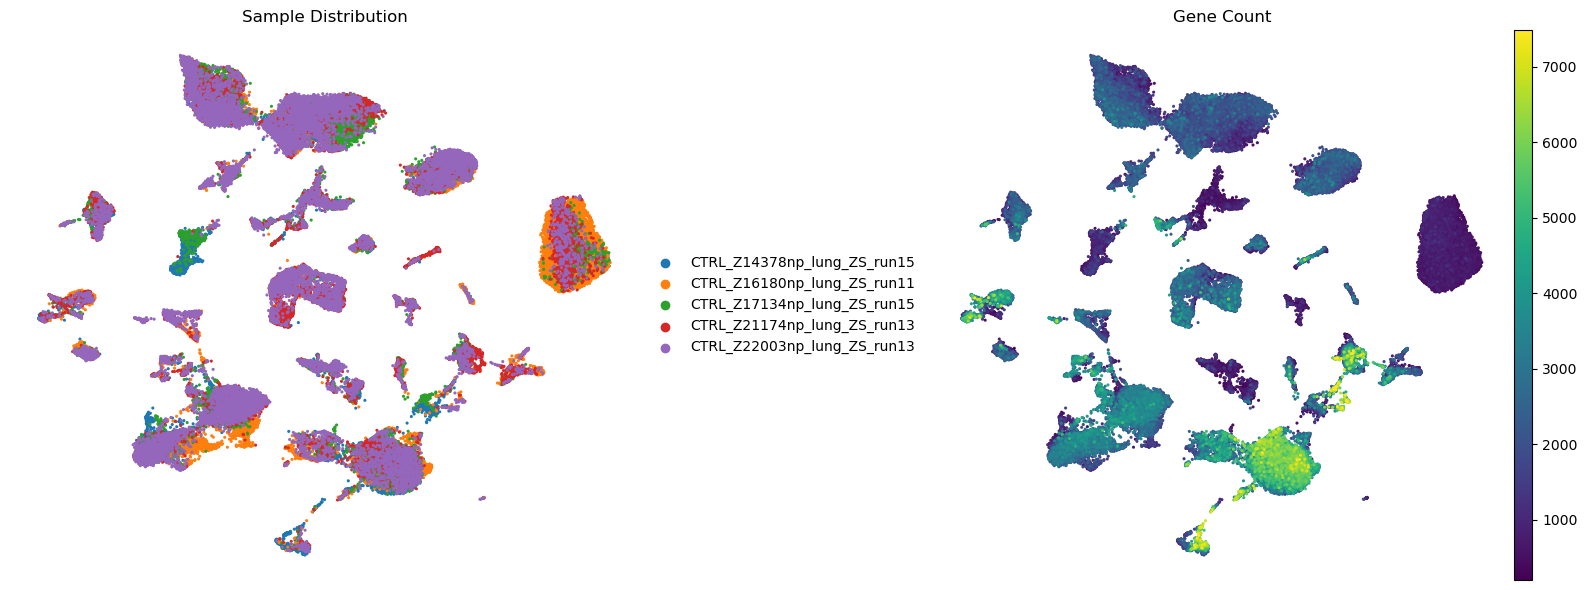

In [12]:
# ── scANVI latent representation ─────────────────────────────
adata_hvg.obsm['X_scanvi'] = scanvi_model.get_latent_representation()
adata_hvg.obs['scanvi_predictions'] = scanvi_model.predict()
adata_hvg.obs['scanvi_prediction_score'] = scanvi_model.predict(soft=True).max(axis=1)

# ── Final neighbors, UMAP, Leiden on scANVI embedding ────────
sc.pp.neighbors(adata_hvg, use_rep='X_scanvi', n_neighbors=30)
sc.tl.umap(adata_hvg, random_state=SEED, min_dist=0.3)
sc.tl.leiden(adata_hvg, resolution=0.5, key_added='leiden', random_state=SEED)
n_clusters = len(adata_hvg.obs['leiden'].unique())
print(f"Final clusters: {n_clusters}")

# ── Silhouette score ─────────────────────────────────────────
sil_score = silhouette_score(adata_hvg.obsm['X_scanvi'], adata_hvg.obs['sample'])
print(f"Silhouette score by sample (scANVI): {sil_score:.3f}")

from sklearn.metrics import adjusted_rand_score
ari = adjusted_rand_score(adata_hvg.obs['leiden_initial'], adata_hvg.obs['leiden'])
print(f"ARI scVI vs scANVI clusters: {ari:.3f}") 

# ── UMAP plots ───────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
sc.pl.umap(adata_hvg, color='sample', ax=axes[0], show=False,
           title='Sample Distribution', frameon=False, s=20)
sc.pl.umap(adata_hvg, color='n_genes_by_counts', ax=axes[1], show=False,
           title='Gene Count', frameon=False, s=20)
plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, 'scanvi_umap.png'), dpi=300, bbox_inches='tight')
plt.show()

SAVE FINAL OUTPUT
==

In [13]:
# ── Transfer results back to full adata ──────────────────────
adata.obsm['X_scvi'] = adata_hvg.obsm['X_scvi']
adata.obsm['X_scanvi'] = adata_hvg.obsm['X_scanvi']
adata.obsm['X_umap'] = adata_hvg.obsm['X_umap']
adata.obs['leiden'] = adata_hvg.obs['leiden']
adata.obs['leiden_initial'] = adata_hvg.obs['leiden_initial']
adata.obs['scanvi_predictions'] = adata_hvg.obs['scanvi_predictions']
adata.obs['scanvi_prediction_score'] = adata_hvg.obs['scanvi_prediction_score']

# ── Save final output ────────────────────────────────────────
adata.write_h5ad(OUTPUT_PATH)
print(f"Saved to {OUTPUT_PATH}")

Saved to /gpfs/projects/kawaldorflab/tykim/python_files/Lung_Atlas/output/scanvi_output_v2.h5ad


UMAP VISUALIZATION
==

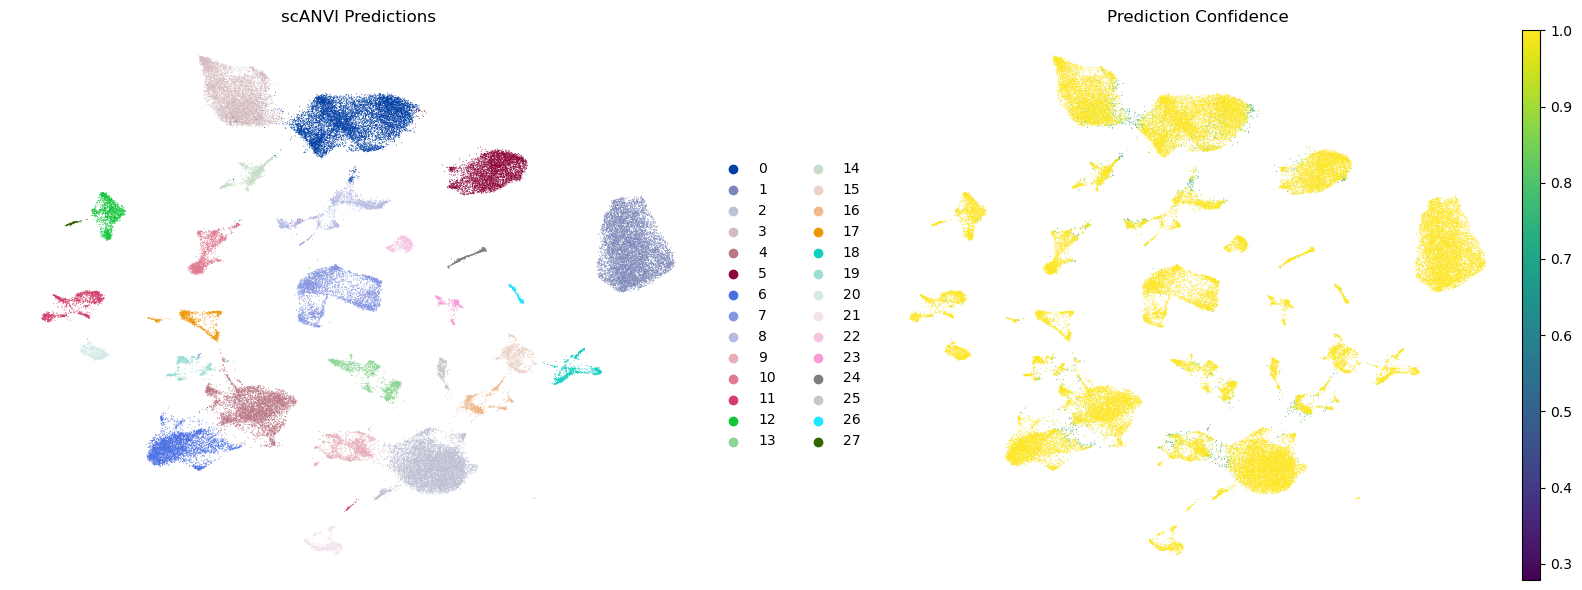

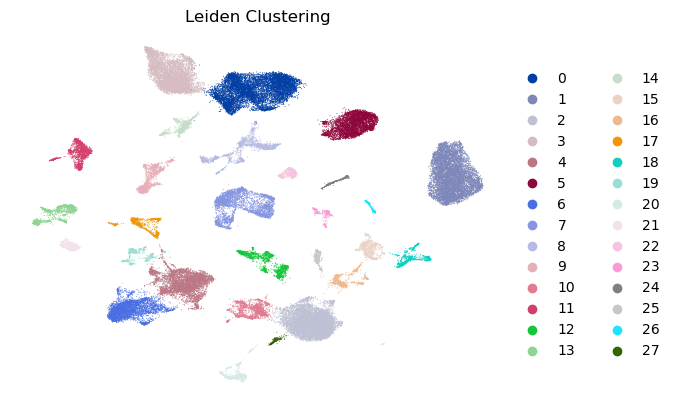

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
sc.pl.umap(adata, color='scanvi_predictions', ax=axes[0], show=False,
           title='scANVI Predictions', frameon=False, legend_loc='right margin')
sc.pl.umap(adata, color='scanvi_prediction_score', ax=axes[1], show=False,
           title='Prediction Confidence', frameon=False, cmap='viridis')
plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, 'scanvi_predictions_umap.png'), dpi=300, bbox_inches='tight')
plt.show()
plt.close()

sc.pl.umap(adata, color='leiden', show=False,
           title='Leiden Clustering', frameon=False, legend_loc='right margin')
plt.savefig(os.path.join(FIGURES_DIR, 'leiden_cluster_umap.png'), dpi=300, bbox_inches='tight')
plt.show()
plt.close()